# Self-Supervision: Rotation Prediction
> Rotation-based self-supervision in plain PyTorch.

# Introduction

This notebook is an introduction to self-supervised learning. In short, self-supervised learning has 2 components:

1. Pretrain on a pretext task, where the labels can come from the data itself
2. Transfer the features, and train on the actual classification labels!

>"What if we can get labels for free for unlabelled data and train unsupervised dataset in a supervised manner? We can achieve this by framing a supervised learning task in a special form to predict only a subset of information using the rest. In this way, all the information needed, both inputs and labels, has been provided. This is known as self-supervised learning." - Lilian Weng

We'll use rotation as a pretext task for learning representations of our data
[[Gidaris et al., ICLR 2018]](https://arxiv.org/abs/1803.07728).

# Experiment Layout

We use [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist): 60k training and 10k test grayscale 28×28 images of 10 clothing classes.

1. Train a model on a rotation prediction task.
    - We use *all* 60k training images, but *none* of their labels.
    - Input: an image rotated by 0°, 90°, 180° or 270°.
    - Target: which of the 4 rotations was applied.
    - To tell how a shirt or a boot is rotated, the model has to learn what shirts and boots look like.

2. Transfer the rotation features to the classification task with *very few* labels: `N_PER_CLASS` images per class.
    - **Linear probe**: freeze the network, train only a linear classifier on its features.
    - **Fine-tuning**: initialize with the rotation weights, train the whole network.

3. Compare with baselines that use the same labeled images and nothing else:
    - logistic regression on raw pixels;
    - linear probe on a frozen *randomly initialized* network;
    - the same network trained from scratch.

Everything is evaluated on the 10k test images.

> In Colab, switch to a GPU first: *Runtime → Change runtime type → T4 GPU*. All the packages are preinstalled.

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("device:", device)

torch.manual_seed(0)
np.random.seed(0)

device: cuda


# Data

In [ ]:
train_ds = torchvision.datasets.FashionMNIST("data/", train=True, download=True)
test_ds = torchvision.datasets.FashionMNIST("data/", train=False, download=True)
CLASSES = train_ds.classes

# The whole dataset fits in memory as a single tensor
MEAN, STD = 0.2860, 0.3530
x_train = ((train_ds.data.float() / 255 - MEAN) / STD).unsqueeze(1)
y_train = train_ds.targets
x_test = ((test_ds.data.float() / 255 - MEAN) / STD).unsqueeze(1)
y_test = test_ds.targets
print(f"{len(x_train)} training samples | {len(x_test)} test samples | {len(CLASSES)} classes")

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.4MB/s]


60000 training samples | 10000 test samples | 10 classes


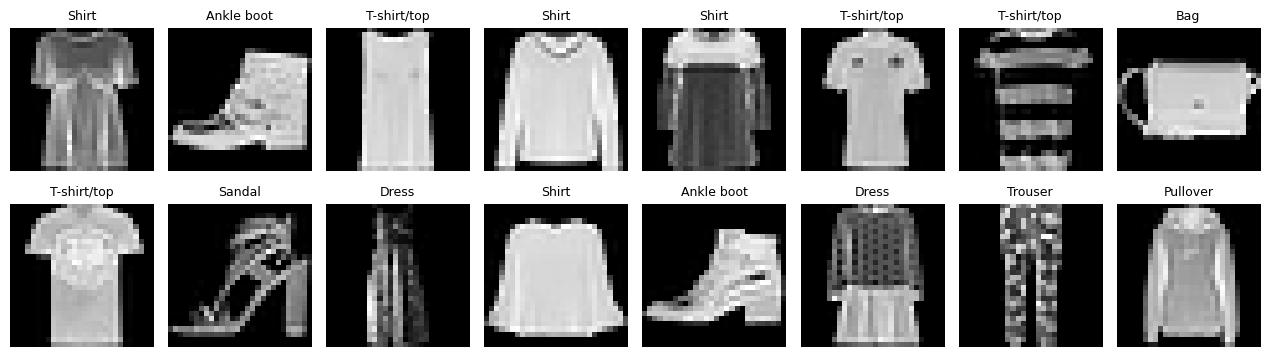

In [ ]:
def show_images(x, titles, ncols=8):
    nrows = (len(x) + ncols - 1) // ncols
    fig, axs = plt.subplots(nrows, ncols, figsize=(1.6 * ncols, 1.9 * nrows))
    for ax in axs.flat:
        ax.axis("off")
    for ax, img, title in zip(axs.flat, x, titles):
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()


idx = torch.randint(len(x_train), (16,))
show_images(x_train[idx], [CLASSES[y] for y in y_train[idx]])

# Model

A small ConvNet. As usual, it has two parts:
- the **body** maps an image to a 128-dimensional feature vector; this is what we transfer;
- the **head** is a single linear layer on top of the features; it is task-specific and is replaced for every new task.

In [ ]:
def conv_bn(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU())


FEAT_DIM = 128


def make_body():
    return nn.Sequential(
        conv_bn(1, 32), conv_bn(32, 32), nn.MaxPool2d(2),  # 28 -> 14
        conv_bn(32, 64), conv_bn(64, 64), nn.MaxPool2d(2),  # 14 -> 7
        conv_bn(64, FEAT_DIM), nn.AdaptiveAvgPool2d(1), nn.Flatten(),
    )


body = make_body()
print(body)
print("parameters:", sum(p.numel() for p in body.parameters()))

Sequential(
  (0): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (1): Sequential(
    (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (4): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (5): MaxPool2d(kernel_size=2, stride=2, paddi

# Rotation Prediction Data

The labels now don't correspond to clothes! They correspond to the rotation: `[0°, 90°, 180°, 270°]`.
Every image in a batch is used in all 4 rotations.

**Question.** Why only multiples of 90°, and not, say, every 45°?

<details><summary>Answer</summary>

Rotating by 90° only permutes pixels, so all 4 versions look equally "natural".
Rotating by 45° cuts off the corners and blurs the image through interpolation,
and the network can detect these artifacts instead of looking at the object.
Such cheap cues that solve the pretext task without learning anything useful are called *shortcuts*.
</details>

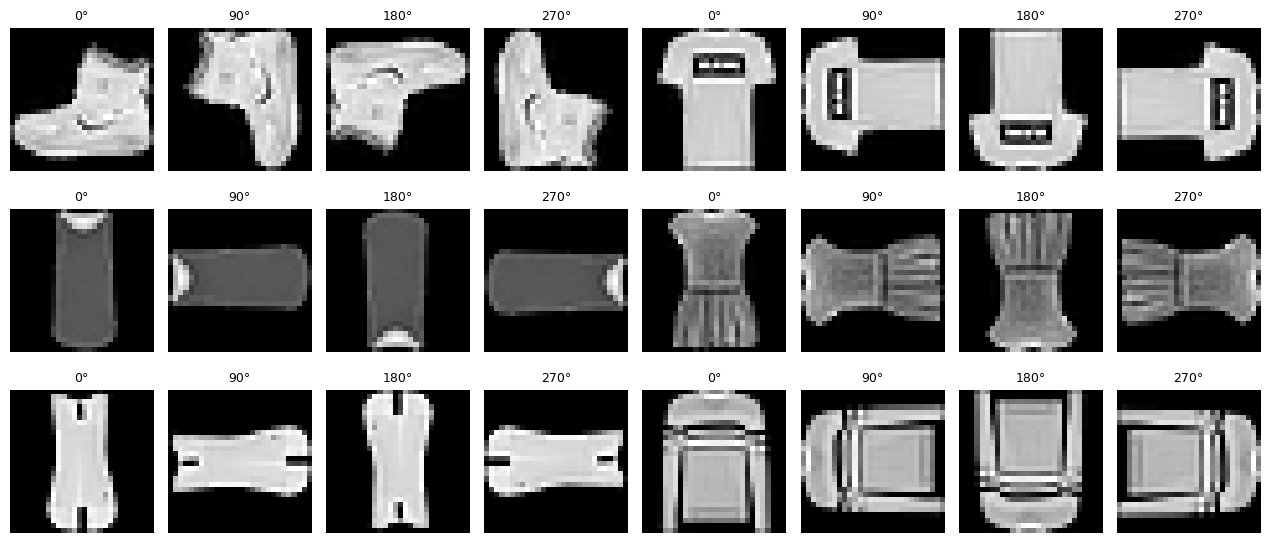

In [ ]:
ANGLES = [0, 90, 180, 270]


def rotate_batch(x):
    """All 4 rotations of every image: returns 4*B images and rotation labels 0..3."""
    xs = [torch.rot90(x, k, dims=(2, 3)) for k in range(4)]
    ys = [torch.full((len(x),), k, dtype=torch.long) for k in range(4)]
    return torch.cat(xs), torch.cat(ys)


x_rot, y_rot = rotate_batch(x_train[:6])
order = torch.arange(len(x_rot)).view(4, 6).T.flatten()  # group the 4 rotations of each image together
show_images(x_rot[order], [f"{ANGLES[y]}°" for y in y_rot[order]], ncols=8)

# Rotation Pretraining

In [ ]:
@torch.no_grad()
def predict(model, x, bs=2000):
    model.eval()
    return torch.cat([model(x[i:i + bs].to(device)).argmax(1).cpu() for i in range(0, len(x), bs)])


x_rot_test, y_rot_test = rotate_batch(x_test)

rot_model = nn.Sequential(make_body(), nn.Linear(FEAT_DIM, 4)).to(device)
N_EPOCHS, BS = 5, 128
opt = torch.optim.Adam(rot_model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=N_EPOCHS * ((len(x_train) + BS - 1) // BS))

for epoch in range(N_EPOCHS):
    t0 = time.time()
    rot_model.train()
    perm = torch.randperm(len(x_train))
    for i in range(0, len(x_train), BS):
        xb, yb = rotate_batch(x_train[perm[i:i + BS]])  # note: class labels are never used
        loss = F.cross_entropy(rot_model(xb.to(device)), yb.to(device))
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    acc =(predict(rot_model, x_rot_test) == y_rot_test).float().mean()
    print(f"epoch {epoch}: loss {loss.item():.3f} | rotation accuracy (test) {acc:.3f} | {time.time() - t0:.0f}s")

# Save the body: these are the self-supervised features we will transfer
rot_body_state = {k: v.cpu().clone() for k, v in rot_model[0].state_dict().items()}

epoch 0: loss 0.108 | rotation accuracy (test) 0.969 | 24s
epoch 1: loss 0.072 | rotation accuracy (test) 0.976 | 24s
epoch 2: loss 0.026 | rotation accuracy (test) 0.979 | 27s
epoch 3: loss 0.010 | rotation accuracy (test) 0.988 | 25s
epoch 4: loss 0.013 | rotation accuracy (test) 0.990 | 25s


Which clothes are hard to "un-rotate"? Let's look at the rotation accuracy per class.
Class labels are used here only for analysis, not for training.

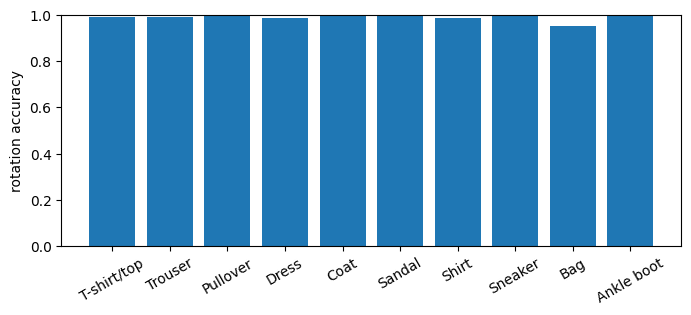

In [ ]:
pred = predict(rot_model, x_rot_test)
cls = y_test.repeat(4)
per_class = [(pred[cls == c] == y_rot_test[cls == c]).float().mean().item() for c in range(10)]
plt.figure(figsize=(8, 3))
plt.bar(CLASSES, per_class)
plt.xticks(rotation=30)
plt.ylabel("rotation accuracy")
plt.ylim(0, 1)
plt.show()

**Question.** Which classes are the hardest, and why?

<details><summary>Answer</summary>

Bags: many of them are nearly symmetric, so a rotated bag looks like another plausible bag.
Footwear is the easiest: a shoe has an obvious sole and toe, so its orientation is never ambiguous.
</details>

# Classification with Few Labels

Now we switch to the original classification task, but pretend that we could afford to label only `N_PER_CLASS` images per class.

100 labeled training samples (0.17% of the training set)


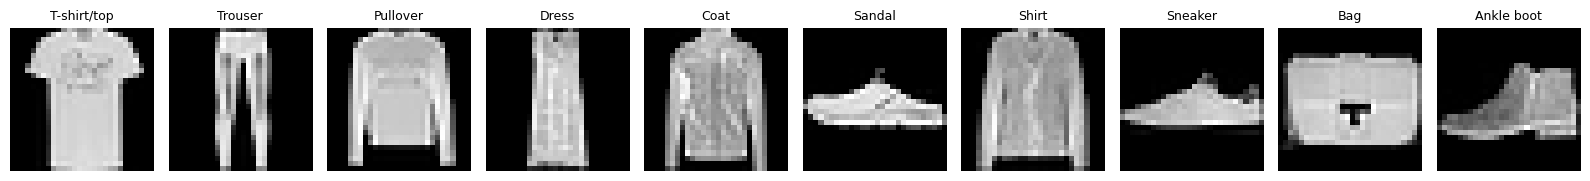

In [ ]:
N_PER_CLASS = 10


def balanced_subset(n_per_class, seed):
    rng = np.random.default_rng(seed)
    idx = [rng.choice(np.where(y_train.numpy() == c)[0], n_per_class, replace=False) for c in range(10)]
    return torch.from_numpy(np.concatenate(idx))


idx = balanced_subset(N_PER_CLASS, seed=0)
x_lab, y_lab = x_train[idx], y_train[idx]
print(f"{len(x_lab)} labeled training samples ({len(x_lab) / len(x_train):.2%} of the training set)")
show_images(x_lab[::N_PER_CLASS], [CLASSES[y] for y in y_lab[::N_PER_CLASS]], ncols=10)

## Linear probe

The standard way to evaluate self-supervised features: freeze the network, extract features, train only a linear classifier (logistic regression) on them.
We compare three feature extractors:
- raw pixels;
- a frozen network with **random** weights: random convolutions are already better than nothing;
- a frozen network pretrained on **rotation prediction**.

In [ ]:
@torch.no_grad()
def extract_features(body, x, bs=2000):
    body.eval()
    return torch.cat([body(x[i:i + bs].to(device)).cpu() for i in range(0, len(x), bs)]).numpy()


def linear_probe(f_train, y, f_test):
    scaler = StandardScaler().fit(f_train)
    clf = LogisticRegression(max_iter=3000).fit(scaler.transform(f_train), y)
    return clf.score(scaler.transform(f_test), y_test.numpy())


torch.manual_seed(1)
random_body_state = {k: v.clone() for k, v in make_body().state_dict().items()}

bodies = {}
for name, state in [("random", random_body_state), ("rotation", rot_body_state)]:
    b = make_body().to(device)
    b.load_state_dict(state)
    bodies[name] = (b, extract_features(b, x_test))


def run_probes(x_lab, y_lab):
    res = {"pixels + logreg": linear_probe(x_lab.flatten(1).numpy(), y_lab.numpy(), x_test.flatten(1).numpy())}
    for name, (b, f_test) in bodies.items():
        res[f"{name} features + logreg"] = linear_probe(extract_features(b, x_lab), y_lab.numpy(), f_test)
    return res


results = run_probes(x_lab, y_lab)
for k, v in results.items():
    print(f"{k:28s} {v:.3f}")

pixels + logreg              0.694
random features + logreg     0.629
rotation features + logreg   0.546


## Fine-tuning vs training from scratch

Now we train the whole network on the labeled images. Both runs use exactly the same architecture, optimizer, number of steps and augmentations (random shifts and horizontal flips).
The only difference is the initialization: random weights or rotation-pretrained weights.

In [ ]:
def augment(x):
    """Random shift by up to 2 px and horizontal flip."""
    x = F.pad(x, (2, 2, 2, 2))
    i, j = np.random.randint(0, 5, size=2)
    x = x[:, :, i:i + 28, j:j + 28]
    flip = torch.rand(len(x)) < 0.5
    x[flip] = x[flip].flip(3)
    return x


def train_classifier(init_state, x, y, steps=1000, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)
    body = make_body()
    if init_state is not None:
        body.load_state_dict(init_state)
    model = nn.Sequential(body, nn.Linear(FEAT_DIM, 10)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    model.train()
    for step in range(steps):
        batch = torch.randint(0, len(x), (64,))
        loss = F.cross_entropy(model(augment(x[batch]).to(device)), y[batch].to(device))
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return (predict(model, x_test) == y_test).float().mean().item()


def run_training(x_lab, y_lab, seed=0):
    return {
        "from scratch": train_classifier(None, x_lab, y_lab, seed=seed),
        "rotation + fine-tune": train_classifier(rot_body_state, x_lab, y_lab, seed=seed),
    }


t0 = time.time()
results.update(run_training(x_lab, y_lab))
print(f"done in {time.time() - t0:.0f}s\n")
for k, v in results.items():
    print(f"{k:28s} {v:.3f}")

done in 13s

pixels + logreg              0.694
random features + logreg     0.629
rotation features + logreg   0.546
from scratch                 0.718
rotation + fine-tune         0.746


# How Many Labels Is Self-Supervision Worth?

One labeled subset is a noisy estimate, so we repeat everything on 3 random subsets for several label budgets.

10 per class done, 40s
30 per class done, 80s
100 per class done, 131s


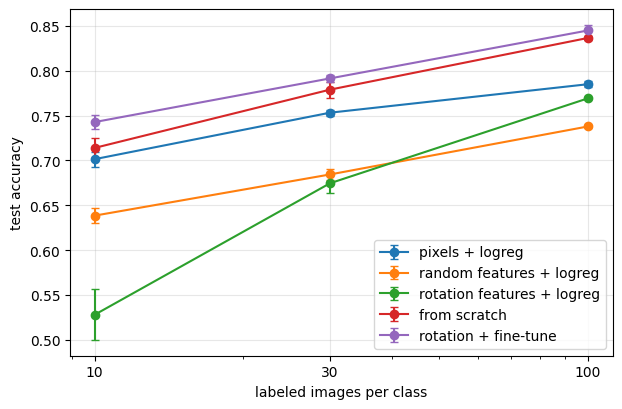

pixels + logreg               10/class: 0.701 ± 0.008 |  30/class: 0.753 ± 0.003 | 100/class: 0.785 ± 0.003
random features + logreg      10/class: 0.639 ± 0.008 |  30/class: 0.684 ± 0.006 | 100/class: 0.738 ± 0.002
rotation features + logreg    10/class: 0.528 ± 0.028 |  30/class: 0.675 ± 0.011 | 100/class: 0.769 ± 0.001
from scratch                  10/class: 0.714 ± 0.011 |  30/class: 0.779 ± 0.009 | 100/class: 0.836 ± 0.002
rotation + fine-tune          10/class: 0.743 ± 0.008 |  30/class: 0.791 ± 0.004 | 100/class: 0.845 ± 0.006


In [ ]:
BUDGETS = [10, 30, 100]
N_SEEDS = 3
curves = {}
t0 = time.time()
for n in BUDGETS:
    for seed in range(N_SEEDS):
        idx = balanced_subset(n, seed)
        res = run_probes(x_train[idx], y_train[idx])
        res.update(run_training(x_train[idx], y_train[idx], seed=seed))
        for k, v in res.items():
            curves.setdefault(k, {}).setdefault(n, []).append(v)
    print(f"{n} per class done, {time.time() - t0:.0f}s")

plt.figure(figsize=(7, 4.5))
for k, by_n in curves.items():
    mean = np.array([np.mean(by_n[n]) for n in BUDGETS])
    std = np.array([np.std(by_n[n]) for n in BUDGETS])
    plt.errorbar(BUDGETS, mean, yerr=std, marker="o", capsize=3, label=k)
plt.xscale("log")
plt.xticks(BUDGETS, [str(n) for n in BUDGETS])
plt.xlabel("labeled images per class")
plt.ylabel("test accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for k, by_n in curves.items():
    print(f"{k:28s} " + " | ".join(f"{n:3d}/class: {np.mean(by_n[n]):.3f} ± {np.std(by_n[n]):.3f}" for n in BUDGETS))

# Conclusion

1. **Free labels give a useful initialization.** Rotation pretraining never sees a class label,
   yet fine-tuning from it beats the same network trained from scratch under identical conditions.
   The fewer labels we have, the more it helps.
2. **High pretext accuracy does not mean good features.** The network predicts rotations almost perfectly,
   but with 10 labels per class a linear classifier on its last-layer features is worse than on a *random* network,
   and with more labels it is only slightly better.
   The last layers specialize in the pretext task ("where is the top?"), not in "what is it?";
   features from the middle of the network transfer better, as in the RotNet paper.
3. **Baselines matter.** Raw pixels and a frozen random ConvNet are far from zero,
   and a from-scratch model must be trained as carefully as the pretrained one, otherwise the comparison says nothing.

The linear probe is the standard way to evaluate self-supervised features, and rotation features are weak at it.
Contrastive methods from the lecture (SimCLR, BYOL) and DINO learn features that work well with just a linear classifier.
SimCLR also faces point 2: it takes the features *before* the projection head, because the layer right before the loss is too task-specific.

**Try it yourself:** change `N_PER_CLASS`, probe the features of intermediate layers,
or replace rotations with another pretext task, e.g. predicting the relative position of two patches [[Doersch et al., ICCV 2015]](https://arxiv.org/abs/1505.05192).